In [80]:
# Import necessary libraries

import numpy as np

import pandas as pd

import seaborn as sns

import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans

from sklearn.metrics import silhouette_score, calinski_harabasz_score

from sklearn.decomposition import PCA

import seaborn as sns

In [82]:
# Load the dataset

df = pd.read_csv("Online_Retail.csv") 

## Data Understanding

#### Data Overview

In [7]:
# Preview the data

print(df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

        InvoiceDate  UnitPrice  CustomerID         Country  
0  01/12/2010 08:26       2.55     17850.0  United Kingdom  
1  01/12/2010 08:26       3.39     17850.0  United Kingdom  
2  01/12/2010 08:26       2.75     17850.0  United Kingdom  
3  01/12/2010 08:26       3.39     17850.0  United Kingdom  
4  01/12/2010 08:26       3.39     17850.0  United Kingdom  


In [9]:
# Basic info and types

print("\nData types and missing values:")

print(df.info())


Data types and missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB
None


In [11]:
# Check missing values

print("\nMissing values per column:")

print(df.isnull().sum())


Missing values per column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [13]:
# Check for duplicate rows

print("\nNumber of duplicate rows:")

print(df.duplicated().sum())


Number of duplicate rows:
5268


#### Exploratory Data Analysis (EDA)

In [15]:
# Displaying summary statistics for key numerical features

df[['Quantity', 'UnitPrice']].describe()

,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


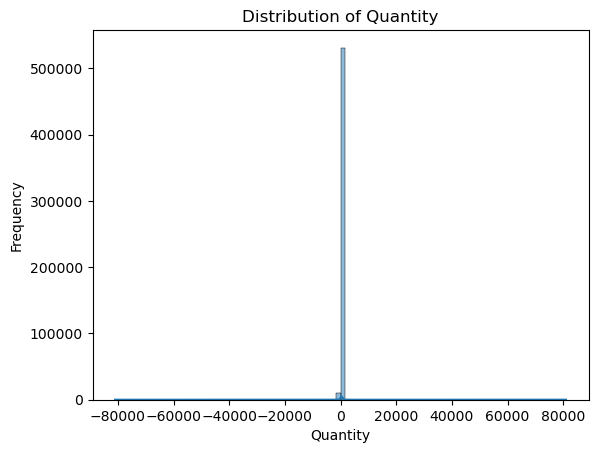

In [17]:
# Visualizing the distribution of 'Quantity'
sns.histplot(df['Quantity'], bins=100, kde=True)
plt.title('Distribution of Quantity')
plt.xlabel('Quantity')
plt.ylabel('Frequency')
plt.show()

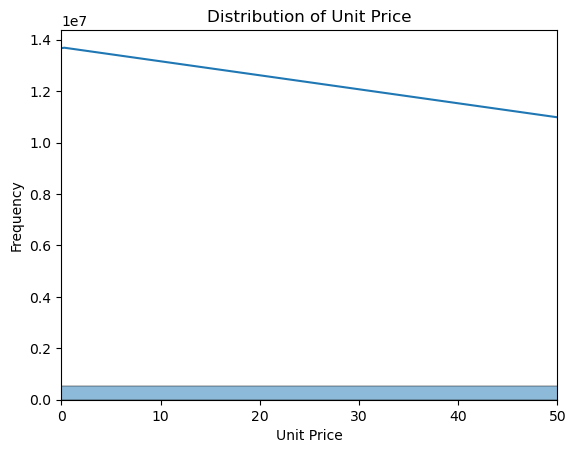

In [19]:
# Visualizing the distribution of 'UnitPrice'

sns.histplot(df['UnitPrice'], bins=100, kde=True)
plt.xlim(0, 50)  # Limiting x-axis for better visualization
plt.title('Distribution of Unit Price')
plt.xlabel('Unit Price')
plt.ylabel('Frequency')
plt.show()

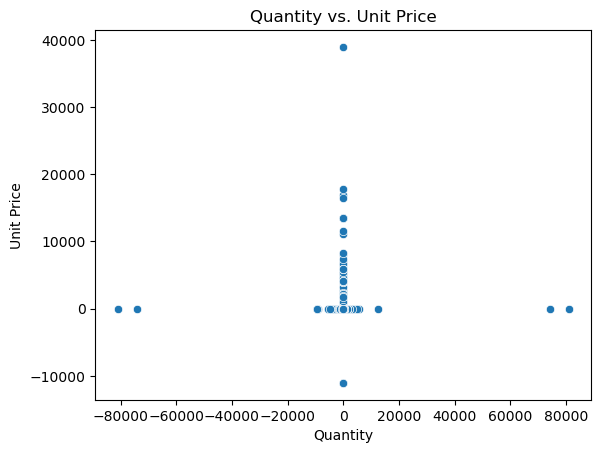

In [21]:
# Scatter plot for Quantity vs. UnitPrice

sns.scatterplot(x='Quantity', y='UnitPrice', data=df)
plt.title('Quantity vs. Unit Price')
plt.xlabel('Quantity')
plt.ylabel('Unit Price')
plt.show()

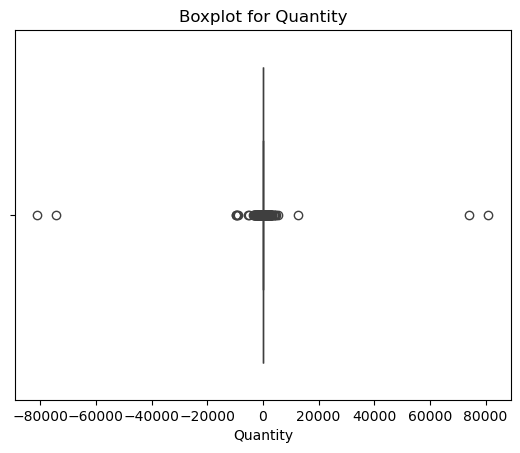

In [23]:
# Boxplot for Quantity to detect outliers

sns.boxplot(x=df['Quantity'])
plt.title('Boxplot for Quantity')
plt.show()

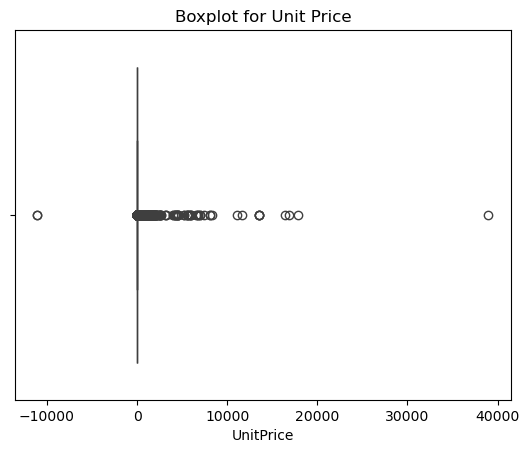

In [25]:
# Boxplot for UnitPrice to detect outliers

sns.boxplot(x=df['UnitPrice'])
plt.title('Boxplot for Unit Price')
plt.show()

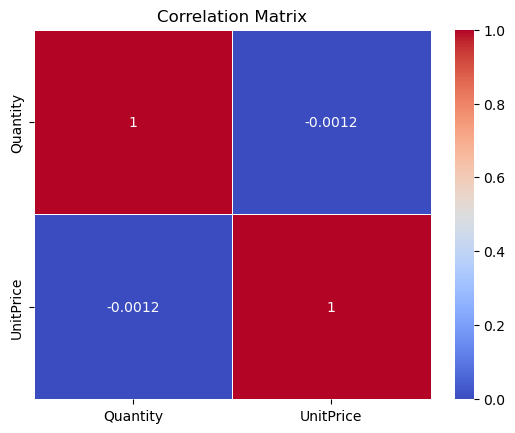

In [27]:
# Plotting the correlation matrix for numeric features

correlation_matrix = df[['Quantity', 'UnitPrice']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

In [29]:
# Checking skewness for both Quantity and UnitPrice

print(f"Skewness of Quantity: {df['Quantity'].skew()}")
print(f"Skewness of UnitPrice: {df['UnitPrice'].skew()}")

Skewness of Quantity: -0.2640763070668848
Skewness of UnitPrice: 186.50697172054137


## Data Preparation

In [31]:
# Drop rows with missing CustomerID

df = df.dropna(subset=['CustomerID'])

In [33]:
# Check for cancelled orders

cancelled_orders = df[df['InvoiceNo'].astype(str).str.contains('C', na=False)]
print("Cancelled Orders:\n", cancelled_orders)

Cancelled Orders:
        InvoiceNo StockCode                       Description  Quantity  \
141      C536379         D                          Discount        -1   
154      C536383    35004C   SET OF 3 COLOURED  FLYING DUCKS        -1   
235      C536391     22556    PLASTERS IN TIN CIRCUS PARADE        -12   
236      C536391     21984  PACK OF 12 PINK PAISLEY TISSUES        -24   
237      C536391     21983  PACK OF 12 BLUE PAISLEY TISSUES        -24   
...          ...       ...                               ...       ...   
540449   C581490     23144   ZINC T-LIGHT HOLDER STARS SMALL       -11   
541541   C581499         M                            Manual        -1   
541715   C581568     21258        VICTORIAN SEWING BOX LARGE        -5   
541716   C581569     84978  HANGING HEART JAR T-LIGHT HOLDER        -1   
541717   C581569     20979     36 PENCILS TUBE RED RETROSPOT        -5   

             InvoiceDate  UnitPrice  CustomerID         Country  
141     01/12/2010 09:41  

In [35]:
# Remove cancelled orders

df = df[~df['InvoiceNo'].astype(str).str.contains('C', na=False)]

In [37]:
# Check for negative or zero quantities and/or prices

invalid_quantities = df[(df['Quantity'] <= 0) | (df['UnitPrice'] <= 0)]
print("Invalid Quantities or Prices:\n", invalid_quantities)

Invalid Quantities or Prices:
        InvoiceNo StockCode                          Description  Quantity  \
9302      537197     22841         ROUND CAKE TIN VINTAGE GREEN         1   
33576     539263     22580         ADVENT CALENDAR GINGHAM SACK         4   
40089     539722     22423             REGENCY CAKESTAND 3 TIER        10   
47068     540372     22090              PAPER BUNTING RETROSPOT        24   
47070     540372     22553               PLASTERS IN TIN SKULLS        24   
56674     541109     22168        ORGANISER WOOD ANTIQUE WHITE          1   
86789     543599    84535B         FAIRY CAKES NOTEBOOK A6 SIZE        16   
130188    547417     22062  CERAMIC BOWL WITH LOVE HEART DESIGN        36   
139453    548318     22055   MINI CAKE STAND  HANGING STRAWBERY         5   
145208    548871     22162          HEART GARLAND RUSTIC PADDED         2   
157042    550188     22636   CHILDS BREAKFAST SET CIRCUS PARADE         1   
187613    553000     47566                   

In [39]:
# Show the count of invalid rows
print("Total rows with invalid Quantity or Price:", invalid_quantities.shape[0])

Total rows with invalid Quantity or Price: 40


In [41]:
# Remove negative or zero quantities and unit prices

df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

In [43]:
# Create TotalPrice feature

df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

In [45]:
# Convert InvoiceDate to datetime

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], dayfirst=True)

In [47]:
# Aggregate to customer level
customer_df = df.groupby('CustomerID').agg({
    'InvoiceNo': 'nunique',
    'Quantity': 'sum',
    'TotalPrice': 'sum',
    'InvoiceDate': ['min', 'max', 'nunique']
}).reset_index()

In [49]:
# Flatten column names

customer_df.columns = ['CustomerID', 'NumInvoices', 'TotalQuantity', 'TotalSpend', 'FirstPurchase', 'LastPurchase', 'PurchaseDays']

In [51]:
# Feature Engineering

customer_df['PurchaseFrequency'] = customer_df['PurchaseDays'] / customer_df['NumInvoices']
customer_df['CustomerPurchaseDays'] = (customer_df['LastPurchase'] - customer_df['FirstPurchase']).dt.days
customer_df['RepeatBuyer'] = customer_df['NumInvoices'].apply(lambda x: 1 if x > 1 else 0)

In [53]:
# Drop date columns for modeling
customer_df = customer_df.drop(columns=['FirstPurchase', 'LastPurchase'])

In [55]:
# Feature Scaling
scaler = StandardScaler()
scaled_features = scaler.fit_transform(customer_df[['TotalSpend', 'TotalQuantity', 'PurchaseFrequency', 'CustomerPurchaseDays']])
scaled_df = pd.DataFrame(scaled_features, columns=['TotalSpend', 'TotalQuantity', 'PurchaseFrequency', 'CustomerPurchaseDays'])
scaled_df['CustomerID'] = customer_df['CustomerID'].values
scaled_df['RepeatBuyer'] = customer_df['RepeatBuyer'].values

In [59]:
# Final prepared dataset

prepared_df = scaled_df
prepared_df.head()

,TotalSpend,TotalQuantity,PurchaseFrequency,CustomerPurchaseDays,CustomerID,RepeatBuyer
0,8.358668,14.473038,0.029251,-0.988065,12346.0,0
1,0.250966,0.251058,0.029251,1.776577,12347.0,1
2,-0.028596,0.227869,0.029251,1.147905,12348.0,1
3,-0.033012,-0.111047,0.029251,-0.988065,12349.0,0
4,-0.191347,-0.197065,0.029251,-0.988065,12350.0,0


In [61]:
# Check class imbalance (if classification target exists)
if 'RepeatBuyer' in prepared_df.columns:
    print("\nClass distribution:")
    print(prepared_df['RepeatBuyer'].value_counts())


Class distribution:
RepeatBuyer
1    2845
0    1493
Name: count, dtype: int64


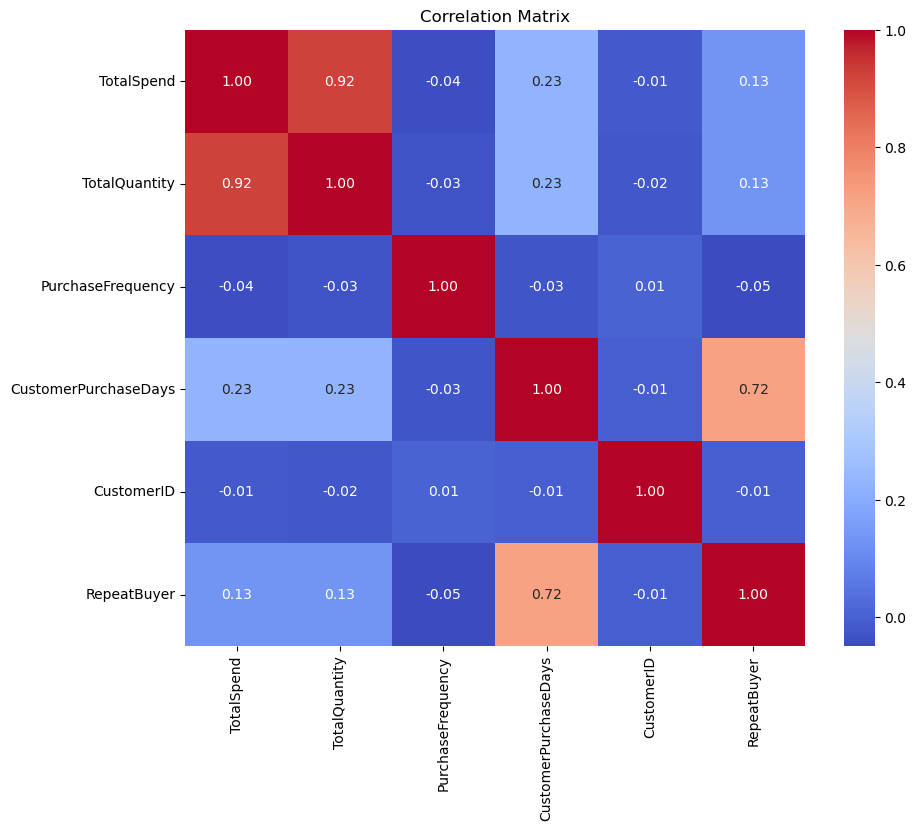

In [63]:
# Correlation heatmap for numerical variables
plt.figure(figsize=(10, 8))
sns.heatmap(prepared_df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

In [65]:
# Compute correlation matrix for numerical variables
correlation_matrix = prepared_df.corr(numeric_only=True)

# Display correlation matrix as a formatted table
print(correlation_matrix.round(2))

                      TotalSpend  TotalQuantity  PurchaseFrequency  \
TotalSpend                  1.00           0.92              -0.04   
TotalQuantity               0.92           1.00              -0.03   
PurchaseFrequency          -0.04          -0.03               1.00   
CustomerPurchaseDays        0.23           0.23              -0.03   
CustomerID                 -0.01          -0.02               0.01   
RepeatBuyer                 0.13           0.13              -0.05   

                      CustomerPurchaseDays  CustomerID  RepeatBuyer  
TotalSpend                            0.23       -0.01         0.13  
TotalQuantity                         0.23       -0.02         0.13  
PurchaseFrequency                    -0.03        0.01        -0.05  
CustomerPurchaseDays                  1.00       -0.01         0.72  
CustomerID                           -0.01        1.00        -0.01  
RepeatBuyer                           0.72       -0.01         1.00  


In [67]:
correlation_matrix.style.format("{:.2f}").set_caption("Correlation Table")

,TotalSpend,TotalQuantity,PurchaseFrequency,CustomerPurchaseDays,CustomerID,RepeatBuyer
TotalSpend,1.00,0.92,-0.04,0.23,-0.01,0.13
TotalQuantity,0.92,1.00,-0.03,0.23,-0.02,0.13
PurchaseFrequency,-0.04,-0.03,1.00,-0.03,0.01,-0.05
CustomerPurchaseDays,0.23,0.23,-0.03,1.00,-0.01,0.72
CustomerID,-0.01,-0.02,0.01,-0.01,1.00,-0.01
RepeatBuyer,0.13,0.13,-0.05,0.72,-0.01,1.00


## Machine Learning Implementation

In [70]:
features_for_clustering = scaled_df[['TotalSpend', 'PurchaseFrequency', 'CustomerPurchaseDays']]

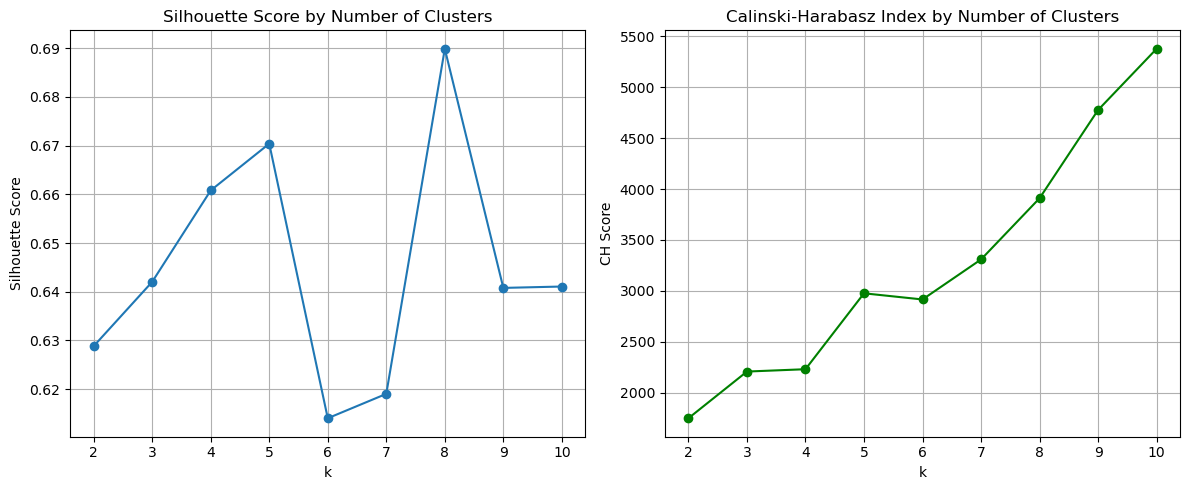

In [74]:
silhouette_scores = []
ch_scores = []
K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(features_for_clustering)
    silhouette_scores.append(silhouette_score(features_for_clustering, labels))
    ch_scores.append(calinski_harabasz_score(features_for_clustering, labels))

# Plot Silhouette Score
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(K, silhouette_scores, marker='o')
plt.title('Silhouette Score by Number of Clusters')
plt.xlabel('k')
plt.ylabel('Silhouette Score')
plt.grid(True)

# Plot Calinski-Harabasz Score
plt.subplot(1, 2, 2)
plt.plot(K, ch_scores, marker='o', color='green')
plt.title('Calinski-Harabasz Index by Number of Clusters')
plt.xlabel('k')
plt.ylabel('CH Score')
plt.grid(True)

plt.tight_layout()
plt.show()

In [76]:
# Train K-Means with optimal k
final_kmeans = KMeans(n_clusters=8, random_state=42)
scaled_df['Cluster'] = final_kmeans.fit_predict(features_for_clustering)

In [78]:
cluster_summary = scaled_df.groupby('Cluster')[['TotalSpend', 'TotalQuantity', 'PurchaseFrequency', 'CustomerPurchaseDays']].mean()
print(cluster_summary)

         TotalSpend  TotalQuantity  PurchaseFrequency  CustomerPurchaseDays
Cluster                                                                    
0          0.054803       0.061076           0.033829              1.044701
1         -0.160612      -0.163701           0.028910             -0.783854
2          0.169663       0.115782          -4.262807              0.970700
3         20.258732      17.532284          -0.581683              1.530951
4          4.932998       5.481340          -0.318090              1.396882
5         -0.186996      -0.187947          28.704990             -0.988065
6         -0.012401       0.099041           8.366456              0.857555
7         -0.118886      -0.123454         -13.352761             -0.915351


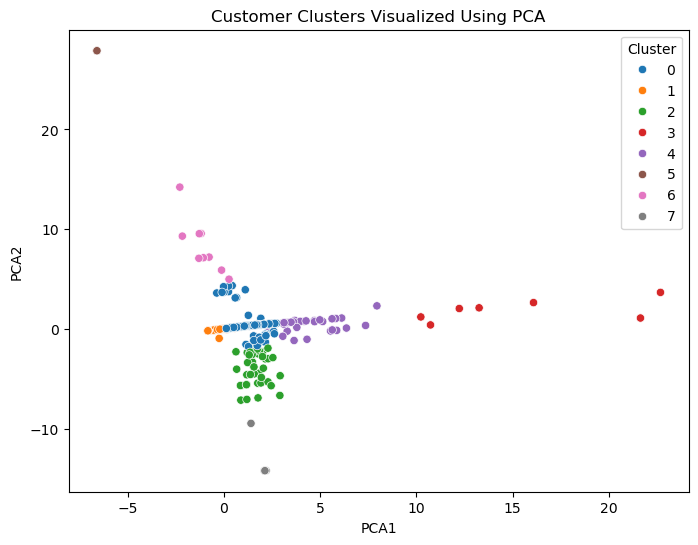

In [84]:
# PCA transformation
pca = PCA(n_components=2)
components = pca.fit_transform(features_for_clustering)
scaled_df['PCA1'] = components[:, 0]
scaled_df['PCA2'] = components[:, 1]

# Plot
plt.figure(figsize=(8, 6))
sns.scatterplot(data=scaled_df, x='PCA1', y='PCA2', hue='Cluster', palette='tab10')
plt.title('Customer Clusters Visualized Using PCA')
plt.show()

In [86]:
scaler = StandardScaler()
features = ['TotalSpend', 'TotalQuantity', 'PurchaseFrequency', 'CustomerPurchaseDays']
scaled_features = scaler.fit_transform(customer_df[features])

# Inverse transform means for interpretation
cluster_means_scaled = scaled_df.groupby('Cluster')[features].mean()
cluster_means_actual = pd.DataFrame(scaler.inverse_transform(cluster_means_scaled), 
                                    columns=features)
cluster_means_actual['Cluster'] = cluster_means_scaled.index
cluster_means_actual = cluster_means_actual.set_index('Cluster')
print(cluster_means_actual)

            TotalSpend  TotalQuantity  PurchaseFrequency  CustomerPurchaseDays
Cluster                                                                       
0          2546.842397    1499.448159           1.000160            268.374504
1           610.651920     365.336026           0.999988             26.960824
2          3579.230698    1775.465116           0.850324            258.604651
3        184143.690000   89650.428571           0.978695            332.571429
4         46393.013871   28847.387097           0.987887            314.870968
5           373.510000     243.000000           2.000000              0.000000
6          1942.806667    1691.000000           1.290741            243.666667
7           985.692000     568.400000           0.533333              9.600000
